# CPU-only Dynamo checks and AI Configurator assessment

This notebook walks through the repository's two separate workflows: `dynamo-check` for static configuration checks and `dynamo-optimize` for NVIDIA AI Configurator's offline sizing. No cell deploys to Kubernetes, runs inference, or requires a local GPU.

The static examples run with `pip install -e .`. The AI Configurator section is opt-in and requires Python 3.11–3.13 plus `pip install -e '.[ai-configurator]'`. Run Jupyter in the same environment. NVIDIA references: [AI Configurator sizing](https://docs.nvidia.com/dynamo/dev/kubernetes/disaggregated-serving/size-with-ai-configurator) and [Dynamo deployment topology](https://docs.nvidia.com/dynamo/dev/kubernetes/model-deployment/deploy-with-dgd).

## 1. Set up the CPU-only environment

Imports below use the local checkout and do not probe a GPU or contact a cluster. Open the notebook from the repository root or `docs/`.

In [8]:
import json
import shutil
import sys
from dataclasses import replace
from pathlib import Path

repo_root = Path.cwd()
if not (repo_root / 'pyproject.toml').exists():
    repo_root = repo_root.parent
assert (repo_root / 'src' / 'llm_optimizer' / 'dynamo.py').exists(), 'Start Jupyter from the repository or docs/'
sys.path.insert(0, str(repo_root / 'src'))

from llm_optimizer.dynamo import AIConfiguratorRequest, build_dynamo_manifest, run_ai_configurator, validate_dynamo_config

print('Repository:', repo_root)
aic_executable = Path(sys.executable).with_name('aiconfigurator')
print('Optional aiconfigurator executable:', aic_executable if aic_executable.is_file() else 'not installed in this kernel')
print('No local GPU detection or Kubernetes access is used.')

Repository: /mnt/c/Users/maorb/work/bento_extend/llm-optimizer
Optional aiconfigurator executable: /home/maorb/.venvs/bento_extend/bin/aiconfigurator
No local GPU detection or Kubernetes access is used.


## 2. Define a hypothetical Kubernetes topology

We **assume**, rather than discover, two nodes with four GPUs each. A single distributed worker using TP=4 and PP=2 consumes eight GPUs. Change these values to reflect a real target cluster before interpreting the result. The model ID is only a label in static checks; no weights are downloaded.

In [9]:
node_count, gpus_per_node = 2, 4
model = 'Qwen/Qwen3-32B-FP8'
configurations = {
    'vllm': {'tensor_parallel_size': 4, 'pipeline_parallel_size': 2, 'max_num_seqs': 64, 'max_num_batched_tokens': 8192},
    'sglang': {'tp_size': 4, 'pp_size': 2, 'max_running_requests': 64, 'max_total_tokens': 8192},
    'trtllm': {'tp_size': 4, 'pp_size': 2, 'max_batch_size': 64, 'max_num_tokens': 8192},
}
print('Hypothetical GPU budget:', node_count * gpus_per_node)
print('Backends:', ', '.join(configurations))

Hypothetical GPU budget: 8
Backends: vllm, sglang, trtllm


## 3. Assess static checks for vLLM, SGLang, and TensorRT-LLM

`validate_dynamo_config` checks positive parallelism and batching values, alias conflicts, some backend-specific topology hints, and `TP × PP × CP = node_count × gpus_per_node`. It reports batch/concurrency caps at **distributed-worker scope**, not independently per physical node. It does not estimate model memory fit, latency, or throughput.

In [10]:
checks = {}
for backend, params in configurations.items():
    check = validate_dynamo_config(backend, params, node_count, gpus_per_node)
    checks[backend] = check
    print(f'{backend}: valid={check.valid}, worker GPUs={check.worker_gpu_count}')
    print('  worker batch/concurrency caps:', check.batch_parameters)
    print('  errors:', check.errors, 'warnings:', check.warnings)
assert all(check.valid for check in checks.values())

vllm: valid=True, worker GPUs=8
  worker batch/concurrency caps: {'max_num_seqs': 64, 'max_num_batched_tokens': 8192}
  errors: [] warnings: []
sglang: valid=True, worker GPUs=8
  worker batch/concurrency caps: {'max_running_requests': 64, 'max_total_tokens': 8192}
  errors: [] warnings: []
trtllm: valid=True, worker GPUs=8
  worker batch/concurrency caps: {'max_batch_size': 64, 'max_num_tokens': 8192}
  errors: [] warnings: []


### Rejected configurations

The next cell deliberately changes one aspect of each configuration. These failures show what the validator can detect; they do not imply it catches every invalid runtime or Kubernetes setting.

In [11]:
bad_cases = {
    'GPU-count mismatch': ('vllm', {'tensor_parallel_size': 2, 'pipeline_parallel_size': 2}),
    'zero batch limit': ('sglang', {'tp_size': 4, 'pp_size': 2, 'max_running_requests': 0}),
    'conflicting TP aliases': ('trtllm', {'tp_size': 4, 'tensor_parallel_size': 8, 'pp_size': 2}),
}
for label, (backend, params) in bad_cases.items():
    check = validate_dynamo_config(backend, params, node_count, gpus_per_node)
    print(label, '->', check.errors)
    assert not check.valid

GPU-count mismatch -> ['distributed worker GPU count mismatch: TP×PP×CP=4, but node_count×gpus_per_node=8']
zero batch limit -> ['max_running_requests must be at least 1']
conflicting TP aliases -> ['conflicting aliases: tensor_parallel_size=8, tp_size=4', 'distributed worker GPU count mismatch: TP×PP×CP=16, but node_count×gpus_per_node=8']


## 4. Generate and inspect a Dynamo manifest

This is the manifest-generation part of `dynamo-check`. It is an in-memory Python dictionary; printing it does not create Kubernetes resources. Check the node count, GPU request per node, and backend command.

In [12]:
manifest = build_dynamo_manifest('vllm', model, configurations['vllm'], node_count, gpus_per_node, name='cpu-assessment-vllm')
worker = manifest['spec']['components'][1]
container = worker['podTemplate']['spec']['containers'][0]
summary = {
    'kind': manifest['kind'], 'name': manifest['metadata']['name'],
    'multinode': worker.get('multinode'),
    'gpu_limit_per_node': container['resources']['limits']['nvidia.com/gpu'],
    'command': container['command'] + container['args'],
}
print(json.dumps(summary, indent=2))
assert worker['multinode']['nodeCount'] == node_count

{
  "kind": "DynamoGraphDeployment",
  "name": "cpu-assessment-vllm",
  "multinode": {
    "nodeCount": 2
  },
  "gpu_limit_per_node": "4",
  "command": [
    "python3",
    "-m",
    "dynamo.vllm",
    "--model",
    "Qwen/Qwen3-32B-FP8",
    "--tensor-parallel-size",
    "4",
    "--pipeline-parallel-size",
    "2",
    "--max-num-seqs",
    "64",
    "--max-num-batched-tokens",
    "8192"
  ]
}


## 5. Assess AI Configurator optimization inputs

AI Configurator searches deployment layouts rather than optimizing an arbitrary `max_num_seqs` or `max_batch_size` grid. Its inputs are model, backend/version, GPU **system model**, total GPU budget, input/output sequence lengths (ISL/OSL), and TTFT/TPOT latency targets. The GPU system definition models hardware and interconnect; it does not inspect live node availability. The support check is important because estimates outside the supported model/system/backend matrix may be weak.

The request below is only a parameter description; creating it does not run the optimizer. Use a backend version matching the runtime you intend to deploy if you have one.

In [13]:
request = AIConfiguratorRequest(
    model=model, framework='vllm', gpu_system='h200_sxm',
    total_gpus=node_count * gpus_per_node,
    input_length=4000, output_length=500,
    ttft_ms=600.0, tpot_ms=20.0,
    backend_version=None, namespace='dynamo',
)
print(json.dumps(request.__dict__, indent=2))
assert request.total_gpus == 8

{
  "model": "Qwen/Qwen3-32B-FP8",
  "framework": "vllm",
  "gpu_system": "h200_sxm",
  "total_gpus": 8,
  "input_length": 4000,
  "output_length": 500,
  "ttft_ms": 600.0,
  "tpot_ms": 20.0,
  "backend_version": null,
  "namespace": "dynamo"
}


## predefined sweeps

In [24]:
from aiconfigurator.cli import cli_exp

result = cli_exp(
    config={
        "agg_custom": {
            "serving_mode": "agg",
            "model_path": request.model,
            "system_name": request.gpu_system,
            "backend_name": request.framework,
            "total_gpus": request.total_gpus,
            "isl": request.input_length,
            "osl": request.output_length,
            "ttft": request.ttft_ms,
            "tpot": request.tpot_ms,
            "agg_num_gpu_candidates": [2, 4, 8],
            "agg_tp_candidates": [1, 2, 4],
            "agg_pp_candidates": [1, 2],
            "agg_dp_candidates": [1],
        }
    },
    save_dir=str(Path.home() / "aic-results" / "custom-grid-1"),
)

print(result.best_configs["agg_custom"].head())

Loading low-fidelity fallback rows for mla_context_module_perf.parquet from /home/maorb/.venvs/bento_extend/lib/python3.12/site-packages/aiconfigurator_core/systems/data/h200_sxm/mla/trtllm/1.3.0rc20/mla_context_module_perf.parquet. Queries returning these rows are framework-implicit and may differ from real backend behavior.
Loading low-fidelity fallback rows for mla_context_module_perf.parquet from /home/maorb/.venvs/bento_extend/lib/python3.12/site-packages/aiconfigurator_core/systems/data/h200_sxm/mla/trtllm/1.3.0rc10/mla_context_module_perf.parquet. Queries returning these rows are framework-implicit and may differ from real backend behavior.
Loading low-fidelity fallback rows for mla_generation_module_perf.parquet from /home/maorb/.venvs/bento_extend/lib/python3.12/site-packages/aiconfigurator_core/systems/data/h200_sxm/mla/trtllm/1.3.0rc20/mla_generation_module_perf.parquet. Queries returning these rows are framework-implicit and may differ from real backend behavior.
Loading lo

                model   isl  osl  prefix  concurrency  request_rate  bs  \
0  Qwen/Qwen3-32B-FP8  4000  500       0            9         0.894   9   
1  Qwen/Qwen3-32B-FP8  4000  500       0           18         1.785   9   
2  Qwen/Qwen3-32B-FP8  4000  500       0            1         0.100   1   
3  Qwen/Qwen3-32B-FP8  4000  500       0            2         0.199   1   

   global_bs     ttft    tpot  ...  num_gen_reqs  num_tokens  ctx_tokens  \
0          9  225.751  19.725  ...           8.0      4008.0        4000   
1          9  226.911  19.751  ...           8.0      4008.0        4000   
2          1  215.857  19.702  ...           1.0      4000.0        4000   
3          1  216.686  19.712  ...           1.0      4000.0        4000   

   gen_tokens  backend  version    system  power_w  \
0         8.0     vllm   0.24.0  h200_sxm      0.0   
1         8.0     vllm   0.24.0  h200_sxm      0.0   
2         1.0     vllm   0.24.0  h200_sxm      0.0   
3         1.0     vllm   0.

Pareto rows: 38


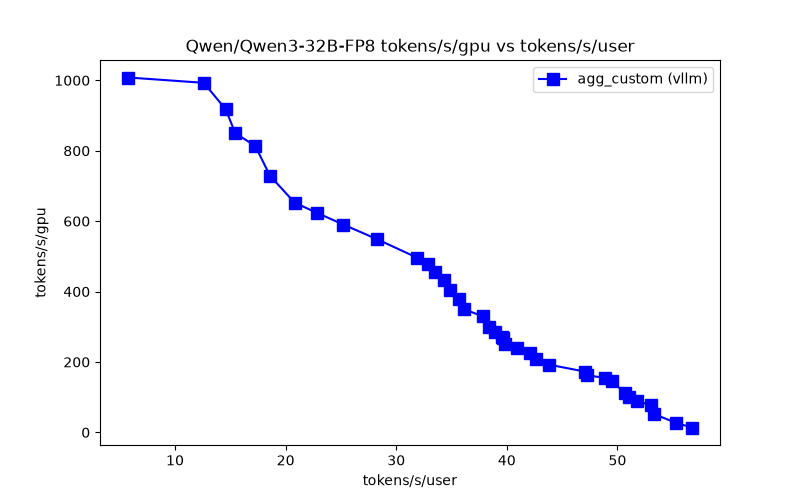

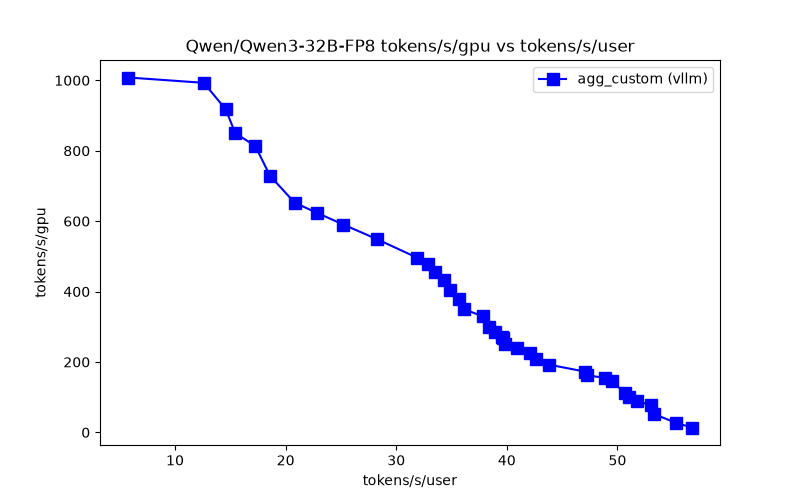

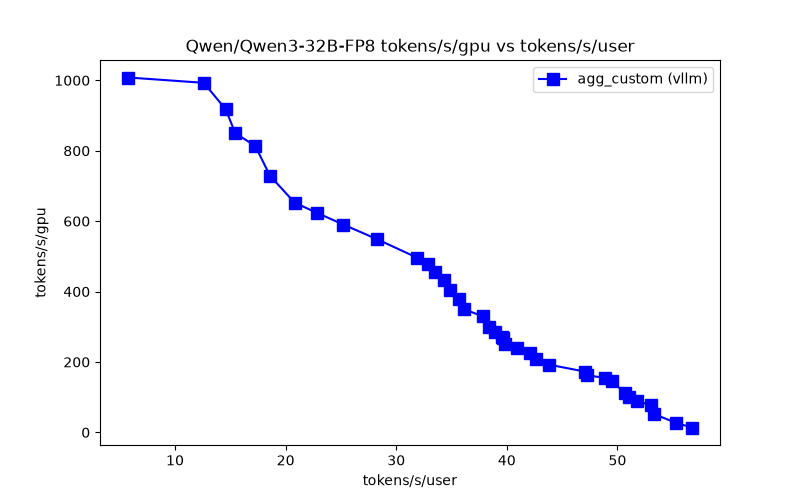

In [27]:
from IPython.display import Image, display

print("Pareto rows:", len(result.pareto_fronts["agg_custom"]))

for plot in Path.home().joinpath("aic-results", "custom-grid-1").rglob("pareto_frontier.png"):
    display(Image(filename=str(plot)))

In [28]:
import logging
import sys
from aiconfigurator.cli.report_and_save import log_final_summary

report_logger = logging.getLogger("aiconfigurator.cli.report_and_save")
handler = logging.StreamHandler(sys.stdout)
handler.setFormatter(logging.Formatter("%(message)s"))

old_level, old_propagate = report_logger.level, report_logger.propagate
report_logger.addHandler(handler)
report_logger.setLevel(logging.INFO)
report_logger.propagate = False

try:
    log_final_summary(
        chosen_exp=result.chosen_exp,
        best_throughputs=result.best_throughputs,
        best_configs=result.best_configs,
        pareto_fronts=result.pareto_fronts,
        tasks=result.tasks,
        mode="exp",
        top_n=5,
    )
finally:
    report_logger.removeHandler(handler)
    report_logger.setLevel(old_level)
    report_logger.propagate = old_propagate


********************************************************************************
*                         AIConfigurator Final Results                         *
********************************************************************************
  ----------------------------------------------------------------------------
  Input Configuration & SLA Target:
    Model: Qwen/Qwen3-32B-FP8 (is_moe: False)
    Total GPUs: 8
    Best Experiment Chosen: agg_custom at 111.51 tokens/s/gpu
  ----------------------------------------------------------------------------
  Overall Best Configuration:
    - Best Throughput: 892.10 tokens/s
    - Per-GPU Throughput: 111.51 tokens/s/gpu
    - Per-User Throughput: 50.70 tokens/s/user
    - Request Rate: 1.79 req/s
    - TTFT: 225.75ms
    - TPOT: 19.73ms
    - Request Latency: 10068.45ms
  ----------------------------------------------------------------------------
  Pareto Frontier:
       Qwen/Qwen3-32B-FP8 Pareto Frontier: tokens/s/gpu_cluster vs tok

### Sensitivity plan

For an apples-to-apples comparison, change **one input at a time**: ISL for prompt-heavy traffic, OSL for generation-heavy traffic, TTFT/TPOT for SLA strictness, and GPU budget for capacity. Hold model, backend/version, and GPU system constant. The following cell lists scenarios only; it does not invent performance results.

In [16]:
scenarios = {
    'baseline': request,
    'longer prompts': replace(request, input_length=8000),
    'longer outputs': replace(request, output_length=1000),
    'tighter TTFT': replace(request, ttft_ms=300.0),
    'tighter TPOT': replace(request, tpot_ms=10.0),
}
for label, item in scenarios.items():
    print(f'{label:16} ISL={item.input_length:5} OSL={item.output_length:5} TTFT={item.ttft_ms:6.0f} TPOT={item.tpot_ms:5.0f}')

baseline         ISL= 4000 OSL=  500 TTFT=   600 TPOT=   20
longer prompts   ISL= 8000 OSL=  500 TTFT=   600 TPOT=   20
longer outputs   ISL= 4000 OSL= 1000 TTFT=   600 TPOT=   20
tighter TTFT     ISL= 4000 OSL=  500 TTFT=   300 TPOT=   20
tighter TPOT     ISL= 4000 OSL=  500 TTFT=   600 TPOT=   10


## 6. Optional CPU-only NVIDIA optimization

Set `RUN_AIC = True` after installing `aisimulate` and selecting a supported model/system/backend. The repository helper calls `aiconfigurator cli support`, then `aiconfigurator cli default` with `--database-mode SILICON` and `--deployment-target dynamo-j2`. It writes ranked CSVs and generated deployment/benchmark artifacts to a fresh directory. It can take time and use CPU/RAM/network, but it does not allocate a GPU. This notebook never executes generated AIPerf scripts or calls `kubectl`.

In [19]:
from concurrent.futures import ThreadPoolExecutor, TimeoutError as FutureTimeout
from tqdm.auto import tqdm

RUN_AIC = True
aic_result = None

if RUN_AIC:
    if not shutil.which("aiconfigurator"):
        raise RuntimeError("Install the AI Configurator extra in this kernel.")

    from datetime import datetime, timezone

    run_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
    artifact_dir = Path.home() / "aic-results" / f"{run_id}"

    with ThreadPoolExecutor(max_workers=1) as pool:
        future = pool.submit(run_ai_configurator, request, str(artifact_dir))
        with tqdm(unit="s", desc="AI Configurator running") as progress:
            while True:
                try:
                    aic_result = future.result(timeout=1)
                    break
                except FutureTimeout:
                    progress.update(1)

    print("Support check:", aic_result["support_check"])
    print("Artifacts:", aic_result["save_dir"])

/home/maorb/.venvs/bento_extend/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
AI Configurator running: 21s [00:22,  1.09s/s]

Support check: 13:47:18 [aiconfigurator] [I] [utils.py:1211] Quant inference result: quant_algo=fp8_block, kv_cache_quant_algo=None, quant_dynamic=True
13:47:18 [aiconfigurator] [I] [utils.py:1318] Loaded model config for Qwen/Qwen3-32B-FP8: architecture=Qwen3ForCausalLM, layers=64, n=64, n_kv=8, d=128, hidden_size=5120, inter_size=25600, vocab=151936, context=40960, topk=0, num_experts=0, moe_inter_size=25600, extra_params={'architecture': 'Qwen3ForCausalLM', 'use_qk_norm': True}
13:47:18 [aiconfigurator] [I] [main.py:2363] Checking support for model=Qwen/Qwen3-32B-FP8, system=h200_sxm, backend=vllm, version=0.24.0

  AIC Support Check Results
  Model:           Qwen/Qwen3-32B-FP8
  System:          h200_sxm
  Backend:         vllm
  Version:         0.24.0
------------------------------------------------------------
  Aggregated Support:    YES
  Disaggregated Support: YES
Artifacts: /home/maorb/aic-results/20260916T104716822922Z


## 7. Review estimates without mistaking them for measurements

When available, `ranked_configurations` contains rows from NVIDIA's `agg/best_config_topn.csv` and `disagg/best_config_topn.csv`. Columns can change across NVIDIA versions. Compare predicted TTFT, TPOT, throughput, TP/PP, worker GPU count, and replicas where present. The optimizer's generated manifests are starting points, not proof of memory fit or actual cluster performance.

In [20]:
if aic_result is None:
    print('No AI Configurator results yet.')
else:
    for topology, rows in aic_result['ranked_configurations'].items():
        print(f'\n{topology}: {len(rows)} ranked candidates')
        for row in rows[:3]:
            print(json.dumps(row, indent=2))
    print('Generated manifests:', [p for p in aic_result['artifacts'] if p.endswith('k8s_deploy.yaml')])
    if not aic_result['ranked_configurations']:
        print('No ranked CSV found; inspect optimizer_output and artifacts before drawing conclusions.')
    print('Optimizer summary excerpt:', aic_result['optimizer_output'][:3000])

Generated manifests: ['Qwen/Qwen3-32B-FP8_h200_sxm_vllm_isl4000_osl500_ttft600_tpot20_200009/agg/top1/k8s_deploy.yaml', 'Qwen/Qwen3-32B-FP8_h200_sxm_vllm_isl4000_osl500_ttft600_tpot20_200009/agg/top2/k8s_deploy.yaml', 'Qwen/Qwen3-32B-FP8_h200_sxm_vllm_isl4000_osl500_ttft600_tpot20_200009/agg/top3/k8s_deploy.yaml', 'Qwen/Qwen3-32B-FP8_h200_sxm_vllm_isl4000_osl500_ttft600_tpot20_200009/disagg/top1/k8s_deploy.yaml']
No ranked CSV found; inspect optimizer_output and artifacts before drawing conclusions.
Optimizer summary excerpt: 13:47:20 [aiconfigurator] [I] [main.py:3032] Loading AIConfigurator version: 0.1.0.dev2
13:47:20 [aiconfigurator] [I] [main.py:3033] Number of top configurations to output: 5 (change with --top-n)
13:47:20 [aiconfigurator] [I] [main.py:3103] Effective parameters: ISL=4000, OSL=500, TTFT=600.0ms, TPOT=20.0ms, backend=vllm
13:47:20 [aiconfigurator] [I] [utils.py:1211] Quant inference result: quant_algo=fp8_block, kv_cache_quant_algo=None, quant_dynamic=True
13:47:20

## 8. Display NVIDIA's generated Pareto visualization

The `default` sweep compares aggregated and disaggregated candidates. NVIDIA normally saves a `pareto_frontier.png` under the run directory, but the helper does not automatically display it. If no PNG exists, inspect the artifact list and optimizer output; an empty frontier or a version-specific output layout may be the cause.

Plots found: ['/home/maorb/aic-results/20260916T104716822922Z/Qwen/Qwen3-32B-FP8_h200_sxm_vllm_isl4000_osl500_ttft600_tpot20_200009/pareto_frontier.png']


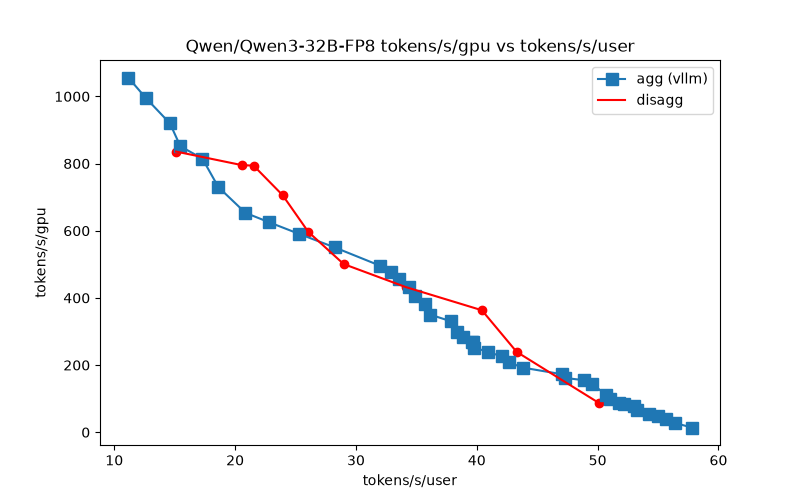

In [21]:
from IPython.display import Image, display

if aic_result is None:
    print('Run the optional AI Configurator cell first.')
else:
    plots = sorted(Path(aic_result['save_dir']).rglob('*pareto*.png'))
    print('Plots found:', [str(plot) for plot in plots])
    for plot in plots:
        display(Image(filename=str(plot)))
    

In [23]:
print('No Pareto PNG found. Artifacts:', aic_result['artifacts'])
print('Output tail:', aic_result['optimizer_output'])

No Pareto PNG found. Artifacts: ['Qwen/Qwen3-32B-FP8_h200_sxm_vllm_isl4000_osl500_ttft600_tpot20_200009/agg/best_config_topn.csv', 'Qwen/Qwen3-32B-FP8_h200_sxm_vllm_isl4000_osl500_ttft600_tpot20_200009/agg/exp_config.yaml', 'Qwen/Qwen3-32B-FP8_h200_sxm_vllm_isl4000_osl500_ttft600_tpot20_200009/agg/pareto.csv', 'Qwen/Qwen3-32B-FP8_h200_sxm_vllm_isl4000_osl500_ttft600_tpot20_200009/agg/top1/bench_run.sh', 'Qwen/Qwen3-32B-FP8_h200_sxm_vllm_isl4000_osl500_ttft600_tpot20_200009/agg/top1/generator_config.yaml', 'Qwen/Qwen3-32B-FP8_h200_sxm_vllm_isl4000_osl500_ttft600_tpot20_200009/agg/top1/k8s_bench.yaml', 'Qwen/Qwen3-32B-FP8_h200_sxm_vllm_isl4000_osl500_ttft600_tpot20_200009/agg/top1/k8s_deploy.yaml', 'Qwen/Qwen3-32B-FP8_h200_sxm_vllm_isl4000_osl500_ttft600_tpot20_200009/agg/top1/per_ops_source.json', 'Qwen/Qwen3-32B-FP8_h200_sxm_vllm_isl4000_osl500_ttft600_tpot20_200009/agg/top1/run_0.sh', 'Qwen/Qwen3-32B-FP8_h200_sxm_vllm_isl4000_osl500_ttft600_tpot20_200009/agg/top1/sflow.yaml', 'Qwen/Qw

## 9. Probe TP, PP, and batch size explicitly

The `default` command already searches candidate parallelism and worker layouts. To understand individual choices, `estimate` evaluates **one fixed configuration** at a time. This small, opt-in grid varies tensor parallelism (TP), pipeline parallelism (PP), and maximum concurrent batch size for aggregated serving. It is not a second optimizer, and these are model estimates—not GPU benchmarks. Some candidates may be unsupported or out of memory; those failures are useful findings. For disaggregated single-point estimates, NVIDIA also accepts separate prefill/decode TP, PP, batch sizes, and worker counts; the default sweep handles their joint layout search.

In [ ]:
RUN_FIXED_ESTIMATES = True  # Set True after the baseline support check succeeds.
fixed_candidates = [
    {'tp': 1, 'pp': 1, 'batch': 16},
    {'tp': 2, 'pp': 1, 'batch': 32},
    {'tp': 4, 'pp': 1, 'batch': 64},
    {'tp': 4, 'pp': 2, 'batch': 64},
]
if RUN_FIXED_ESTIMATES:
    import subprocess
    assert aic_executable.is_file(), 'Select the WSL kernel with aisimulate installed.'
    assert aic_result is not None, 'Run the baseline support check and sweep first.'
    for candidate in fixed_candidates:
        if candidate['tp'] * candidate['pp'] > request.total_gpus:
            print('Skipping over-budget candidate:', candidate)
            continue
        command = [
            str(aic_executable), 'cli', 'estimate',
            '--model-path', request.model, '--system', request.gpu_system,
            '--backend', request.framework, '--estimate-mode', 'agg',
            '--database-mode', 'SILICON', '--isl', str(request.input_length),
            '--osl', str(request.output_length), '--tp-size', str(candidate['tp']),
            '--pp-size', str(candidate['pp']), '--batch-size', str(candidate['batch']),
            '--detail', 'memory,time',
        ]
        if request.backend_version:
            command += ['--backend-version', request.backend_version]
        completed = subprocess.run(command, text=True, capture_output=True, timeout=180)
        print('\nCandidate:', candidate, '| exit code:', completed.returncode)
        print((completed.stdout + completed.stderr)[-5000:])
else:
    print('Fixed estimates skipped. Set RUN_FIXED_ESTIMATES=True to compare TP/PP/batch candidates.')

## 10. Rerun the full optimizer with additional controls

These are **scenario inputs and constraints**, not parameters that the optimizer magically tunes: `--prefix` assumes reusable prefix tokens, `--free-gpu-memory-fraction` limits the KV-cache budget, and `--strict-sla` filters the Pareto frontier to SLA-compliant candidates. The optimizer then searches layouts again under each changed assumption. Run only the variants you select; each run uses a fresh directory and may take several minutes. The baseline remains available in `aic_result`.

In [ ]:
RUN_EXTRA_SWEEPS = False  # Opt in; each selected case invokes another full sweep.
extra_cases = {
    'prefix_1024': ['--prefix', '1024'],
    'kv_fraction_085': ['--free-gpu-memory-fraction', '0.85'],
    'strict_sla': ['--strict-sla'],
}
selected_cases = ['prefix_1024']  # Add names from extra_cases only if needed.
extra_results = {}
if RUN_EXTRA_SWEEPS:
    import subprocess
    assert aic_result is not None, 'Run the baseline sweep first.'
    for name in selected_cases:
        assert name in extra_cases, f'Unknown case: {name}'
        output_dir = Path(aic_result['save_dir']).parent / (Path(aic_result['save_dir']).name + '_' + name)
        assert not output_dir.exists(), f'Choose a fresh output directory: {output_dir}'
        command = list(aic_result['commands']['optimize'])
        command[command.index('--save-dir') + 1] = str(output_dir)
        command.extend(extra_cases[name])
        completed = subprocess.run(command, text=True, capture_output=True, timeout=600)
        extra_results[name] = {'returncode': completed.returncode, 'save_dir': str(output_dir)}
        print('\nScenario:', name, '| exit code:', completed.returncode, '| directory:', output_dir)
        print((completed.stdout + completed.stderr)[-3000:])
        for plot in sorted(output_dir.rglob('*pareto*.png')):
            display(Image(filename=str(plot)))
else:
    print('Additional sweeps skipped. Set RUN_EXTRA_SWEEPS=True to run selected_cases.')

## 11. Equivalent CLI commands

The Python cells above mirror these separate CLI operations. The first command is static and CPU-only. The second invokes the optional CPU-only NVIDIA optimizer; its output directory must be new or empty. Neither command below uses `--check-cluster`, so neither contacts Kubernetes.

```bash
llm-optimizer dynamo-check --framework vllm --model Qwen/Qwen3-32B-FP8 \
  --node-count 2 --gpus-per-node 4 \
  --server-args 'tensor_parallel_size=4;pipeline_parallel_size=2;max_num_seqs=64;max_num_batched_tokens=8192'

llm-optimizer dynamo-optimize --framework vllm --model Qwen/Qwen3-32B-FP8 \
  --node-count 2 --gpus-per-node 4 --gpu-system h200_sxm \
  --input-len 4000 --output-len 500 --ttft 600 --tpot 20 \
  --artifacts-dir results/aic-new-run
```

## 12. Conclusions and next validation boundary

- Static checks can reject inconsistent topology or invalid batch limits and create a DGD manifest. They cannot establish model fit, available nodes, or good latency.
- AI Configurator offers CPU-only, support-matrix-dependent estimates and ranked layouts. Its GPU budget and interconnect model are assumptions, not live cluster observations.
- Neither path measures serving performance. On a real GPU cluster, separately validate the generated manifest, backend/model compatibility, memory use, and TTFT/TPOT/throughput with AIPerf before deployment decisions.

No Kubernetes deployment or GPU benchmark is performed here.